# CS 463 Project — Evaluation and Model Selection

Compares every trained model in all three states and picks the final model.
The test set is used for the first time in this notebook.

**Run after** `03_Modeling.ipynb` and `04_Neural_Networks.ipynb` have run for
CA, TX and WI. This notebook loads only XGBoost and scikit-learn models (no
PyTorch), so all three states run in one process:

```
.venv/bin/jupyter nbconvert --to notebook --execute --inplace 05_Evaluation.ipynb
```

## Narrowing 33 models down to one

11 model types × 3 states = 33 trained models. They are narrowed down in
two stages, and the test set is used only in the second:

1. **Validation leaderboard.** Every model is scored on the validation
   period (2014-10-08 to 2015-07-16) in every state.
2. **Shortlist.** Models are ranked by validation RMSE within each state, and
   the ranks are averaged across states. The **top 3 make the shortlist**.
   The 28-day-average baseline is kept for reference.
3. **Test.** Only the shortlisted models are scored on the test period
   (2015-07-17 to 2016-04-24), once. The **final model is the validation
   winner**. The test score is its honest estimate of future accuracy, not
   a second chance to choose.

All scores use **non-stockout rows**. On a suspected stockout the shelf was
empty, so recorded sales of 0 say nothing about demand.

## Metrics

| Metric | What it measures | Why it is here |
|---|---|---|
| **RMSE** (selection metric) | Square root of the mean squared miss, in units | Its best forecast is the *mean*, which is what stock planning needs. Big misses on fast sellers are penalized most. Same criterion used for tuning in 03 |
| **WAPE** (headline) | Total absolute miss ÷ total units sold | Easy to read ("off by X% of units"), works with zero sales, comparable across states |
| MAE | Mean absolute miss, in units | Plain-language size of a typical miss |
| Bias | Mean forecast ÷ mean actual − 1 | Shows whether the model over-orders (+) or under-orders (−) |
| Poisson deviance | How well the forecast works as an expected count | Matches the Poisson / Tweedie losses used in training |
| RMSSE | Each series' RMSE ÷ its typical day-to-day change, averaged over series | Scale-free. The M5 competition's metric family, so slow and fast sellers count equally |
| R² | Share of sales variance explained | Reference only: on zero-heavy data it is driven by a few very high-sales days |

**Why not select on WAPE or MAE?** For a day with a 60% chance of 0 sales,
MAE is lowest for a forecast of 0, the *median*. On zero-heavy data,
MAE-type metrics reward forecasts that run low, which would leave shelves
short. **MAPE is left out** because it divides by actual sales, which are 0
on most days.

In [1]:
import re

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb

from src import config
from src import data_prep as dp
from src import models as m
from src.evaluation import METRICS, forecast_value, regression_report, rmsse_scales

OUT_DIR = config.RESULTS_DIR / "evaluation"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

STATES = list(config.STATES)
BASELINE = "Baseline: 28-day average"
SHORTLIST_SIZE = 3

# Chart colors: one fixed color per state (categorical slots 1-3), gray for context
STATE_COLORS = {"CA": "#2a78d6", "TX": "#eb6834", "WI": "#1baf7a"}
MUTED = "#b5b3ac"
INK, INK_2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})

FMT = {"MAE": "{:.3f}", "RMSE": "{:.3f}", "WAPE": "{:.1%}", "Bias": "{:+.1%}",
       "Poisson deviance": "{:.3f}", "RMSSE": "{:.3f}", "R2": "{:.3f}"}


def model_type(name):
    '''Returns the model type with its tuned setting removed, e.g. "Ridge (alpha=10)" -> "Ridge".

    Tuned settings differ by state, so this is the name used to compare one
    model type across states.
    '''
    name = re.sub(r" \((alpha|p)=[^)]*\)", "", name)
    return re.sub(r"\(Tweedie, p=[^)]*\)", "(Tweedie)", name)


def series_key(frame):
    '''Returns the "store_id|item_id" key of each row.'''
    return (frame["store_id"].astype(str) + "|" + frame["item_id"].astype(str)).to_numpy()


def save(fig, name):
    '''Saves a figure for the slides and shows it.'''
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

## 1. RMSSE scales

RMSSE divides each series' error by how much its sales normally change from
one day to the next during training. The scales come from the raw sales file,
from each series' first sale up to the end of training.

In [2]:
raw_sales = pd.read_csv(config.SALES_FILE)
scales = {state: rmsse_scales(state, raw_sales) for state in STATES}
del raw_sales
pd.DataFrame({state: s.describe() for state, s in scales.items()}).T[["count", "mean", "50%", "max"]].style.format("{:,.2f}")

,count,mean,50%,max
CA,"11,432.00",9.71,1.96,"6,087.58"
TX,"8,824.00",8.21,1.50,"3,481.43"
WI,"8,824.00",7.62,1.42,"1,938.63"


## 2. Stage 1 — validation leaderboard (all 33 models)

The forecasts were saved by 03 and 04, so nothing is retrained here.

In [3]:
val_rows = []
for state in STATES:
    pred = pd.read_parquet(config.RESULTS_DIR / state / "validation_predictions.parquet")
    pred = pred[pred["is_suspected_stockout"] == 0]
    y, series = pred["target_sales"].to_numpy(), series_key(pred)
    model_columns = [c for c in pred.columns if c.startswith("Baseline") or pred[c].dtype == np.float32]
    for name in model_columns:
        val_rows.append({"state": state, "model": model_type(name), "tuned name": name,
                         **regression_report(y, pred[name], series, scales[state])})
    del pred

validation = pd.DataFrame(val_rows)
validation["RMSE rank"] = validation.groupby("state")["RMSE"].rank()
validation.to_csv(OUT_DIR / "validation_leaderboard.csv", index=False)
print(f"{len(validation)} models scored ({validation['model'].nunique()} types x {len(STATES)} states)")

33 models scored (11 types x 3 states)


### 2.1 Average across states

One row per model type: the average rank by RMSE across the three states,
plus each metric averaged across states. Sorted best first.

In [4]:
leaderboard = (validation.groupby("model")
               .agg(**{"avg RMSE rank": ("RMSE rank", "mean")}, **{k: (k, "mean") for k in METRICS})
               .sort_values(["avg RMSE rank", "RMSE"]))
leaderboard.style.format({"avg RMSE rank": "{:.1f}", **FMT}).background_gradient(subset=["avg RMSE rank"], cmap="Greens_r")

,avg RMSE rank,MAE,RMSE,WAPE,Bias,Poisson deviance,RMSSE,R2
model,,,,,,,,
XGBoost (Tweedie),1.3,0.992,2.115,69.1%,-0.9%,1.371,0.809,0.684
Hurdle model (XGBoost + XGBoost),2.0,0.995,2.123,69.3%,-0.3%,1.369,0.810,0.681
XGBoost (squared error),2.7,1.009,2.134,70.3%,+0.6%,1.396,0.818,0.678
MLP,4.0,1.006,2.161,70.0%,-1.3%,1.393,0.815,0.670
Random Forest,5.0,1.016,2.169,70.7%,+0.3%,1.411,0.820,0.667
LSTM,6.0,1.030,2.208,71.7%,+2.1%,1.456,0.831,0.655
LASSO,7.7,1.037,2.225,72.2%,+0.2%,1.722,0.860,0.649
Linear Regression,8.0,1.036,2.225,72.2%,+0.2%,1.743,0.861,0.650
Ridge,8.3,1.036,2.225,72.2%,+0.2%,1.743,0.861,0.649


### 2.2 Improvement over the 28-day-average baseline

Each state's RMSE is shown as a percent improvement over the baseline in
that state. This makes the states comparable even though their sales volumes
differ. Gray bars are models that did not make the shortlist.

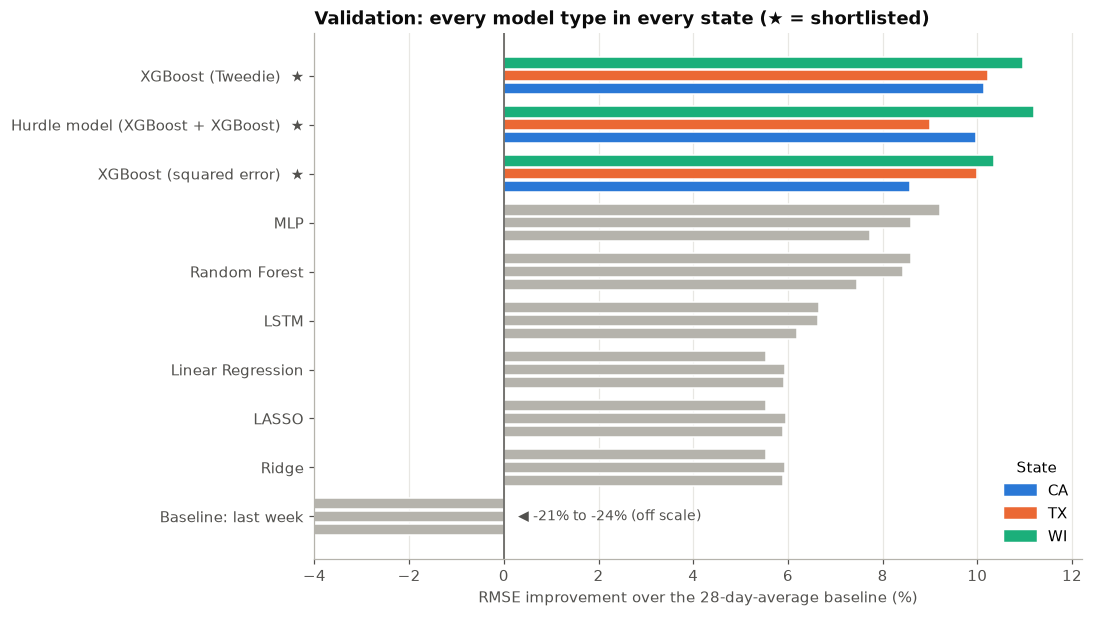

In [5]:
base_rmse = validation[validation["model"] == BASELINE].set_index("state")["RMSE"]
validation["RMSE gain vs baseline"] = 1 - validation["RMSE"] / validation["state"].map(base_rmse)

shortlist = [m_ for m_ in leaderboard.index if not m_.startswith("Baseline")][:SHORTLIST_SIZE]
order = (validation[validation["model"] != BASELINE].groupby("model")["RMSE gain vs baseline"].mean()
         .sort_values().index)

fig, ax = plt.subplots(figsize=(9, 6.2))
height = 0.26
for i, state in enumerate(STATES):
    gains = validation[validation["state"] == state].set_index("model").reindex(order)["RMSE gain vs baseline"]
    colors = [STATE_COLORS[state] if name in shortlist else MUTED for name in order]
    ax.barh(np.arange(len(order)) + (i - 1) * height, gains * 100, height=height - 0.03,
            color=colors, label=state, edgecolor="white", linewidth=1)
ax.axvline(0, color=INK_2, linewidth=1)
# The last-week baseline is far below 0; clip the axis so the real differences stay visible
worst = validation.loc[validation["model"] == "Baseline: last week", "RMSE gain vs baseline"]
ax.set_xlim(-4, max(12, validation["RMSE gain vs baseline"].max() * 100 + 1))
ax.text(0.3, list(order).index("Baseline: last week"), f"◀ {worst.max():.0%} to {worst.min():.0%} (off scale)",
        va="center", ha="left", fontsize=9, color=INK_2)
ax.set_yticks(np.arange(len(order)), [f"{n}  ★" if n in shortlist else n for n in order])
ax.set_xlabel("RMSE improvement over the 28-day-average baseline (%)")
ax.set_title("Validation: every model type in every state (★ = shortlisted)", loc="left")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in STATES]
ax.legend(handles, STATES, title="State", loc="lower right")
ax.grid(axis="y", visible=False)
save(fig, "01_validation_improvement")

## 3. Shortlist

The three model types with the best average RMSE rank go on to the test set.

In [6]:
final_model = shortlist[0]
print("Shortlist:", shortlist)
print("Final model (validation winner):", final_model)

validation.pivot(index="model", columns="state", values="RMSE rank").loc[leaderboard.index].astype(int)

Shortlist: ['XGBoost (Tweedie)', 'Hurdle model (XGBoost + XGBoost)', 'XGBoost (squared error)']
Final model (validation winner): XGBoost (Tweedie)


state,CA,TX,WI
model,,,
XGBoost (Tweedie),1,1,2
Hurdle model (XGBoost + XGBoost),2,3,1
XGBoost (squared error),3,2,3
MLP,4,4,4
Random Forest,5,5,5
LSTM,6,6,6
LASSO,9,7,7
Linear Regression,7,9,8
Ridge,8,8,9


## 4. Stage 2 — test set (shortlist only)

Each shortlisted model is loaded from `models/<state>/` and makes forecasts
for the test period. The 28-day-average baseline (already a column in the
data) is scored alongside it. Forecasts are saved to
`results/<state>/test_predictions.parquet`.

Only XGBoost and scikit-learn models can be loaded here. If the shortlist ever
includes the MLP or LSTM, their test forecasts would need a separate PyTorch
run (see `src/models.py` for why the libraries are kept apart).

In [7]:
def load_model(state, model):
    '''Loads one saved classical model for a state, by model type.'''
    directory = config.MODELS_DIR / state
    xgb_files = {"XGBoost (squared error)": "xgb_squared_error.json", "XGBoost (Tweedie)": "xgb_tweedie.json"}
    joblib_files = {"Linear Regression": "linear_regression.joblib", "Ridge": "ridge.joblib",
                    "LASSO": "lasso.joblib", "Random Forest": "random_forest.joblib"}
    if model in xgb_files:
        booster = xgb.XGBRegressor()
        booster.load_model(directory / xgb_files[model])
        return booster
    if model in joblib_files:
        return joblib.load(directory / joblib_files[model])
    if model.startswith("Hurdle"):
        return m.HurdleRegressor.load(directory / "hurdle")
    raise NotImplementedError(f"{model}: neural networks are scored in a PyTorch process, not here")


test_models = [BASELINE] + shortlist
test_rows, test_store = [], {}
for state in STATES:
    features = dp.load_features(state)
    meta = ["store_id", "item_id", "cat_id", "date", "target_sales", "is_suspected_stockout", "sell_price", "zero_share_91"]
    test = dp.load_split(state, "test", list(dict.fromkeys(meta + features)))

    out = test[meta].copy()
    out[BASELINE] = test["rolling_mean_28"].astype(np.float32)
    for model in shortlist:
        out[model] = np.maximum(0, load_model(state, model).predict(test[features])).astype(np.float32)
    del test
    out.to_parquet(config.RESULTS_DIR / state / "test_predictions.parquet", index=False)

    clean = out[out["is_suspected_stockout"] == 0]
    for model in test_models:
        test_rows.append({"state": state, "model": model,
                          **regression_report(clean["target_sales"], clean[model], series_key(clean), scales[state])})
    test_store[state] = out
    print(f"{state}: {len(out):,} test rows, {len(clean):,} without suspected stockouts")

test_results = pd.DataFrame(test_rows)
test_results.to_csv(OUT_DIR / "test_results.csv", index=False)

CA: 3,411,891 test rows, 2,959,515 without suspected stockouts


TX: 2,573,698 test rows, 2,212,190 without suspected stockouts


WI: 2,574,436 test rows, 2,219,695 without suspected stockouts


### 4.1 Test results, every metric

Best value per state in bold (closest to 0 for Bias, highest for R²).

In [8]:
def bold_best(frame):
    '''Bolds the best model per state and metric.'''
    styles = pd.DataFrame("", index=frame.index, columns=frame.columns)
    for state in frame.index.get_level_values("state").unique():
        rows = frame.xs(state, level="state", drop_level=False)
        for metric in frame.columns:
            values = rows[metric].abs() if metric == "Bias" else rows[metric]
            best = values.idxmax() if metric == "R2" else values.idxmin()
            styles.loc[best, metric] = "font-weight: bold"
    return styles


table = test_results.set_index(["state", "model"])[METRICS]
table.style.format(FMT).apply(bold_best, axis=None)

### 4.2 Did validation predict test?

If the shortlist keeps the same order and the scores move by similar amounts
between validation and test, the selection was not a lucky fit to the
validation period.

In [9]:
gap = (validation[validation["model"].isin(test_models)][["state", "model", "RMSE", "WAPE"]]
       .merge(test_results[["state", "model", "RMSE", "WAPE"]], on=["state", "model"], suffixes=(" val", " test")))
gap["RMSE change"] = gap["RMSE test"] / gap["RMSE val"] - 1
gap.set_index(["state", "model"]).style.format({"RMSE val": "{:.3f}", "RMSE test": "{:.3f}", "WAPE val": "{:.1%}",
                                                "WAPE test": "{:.1%}", "RMSE change": "{:+.1%}"})

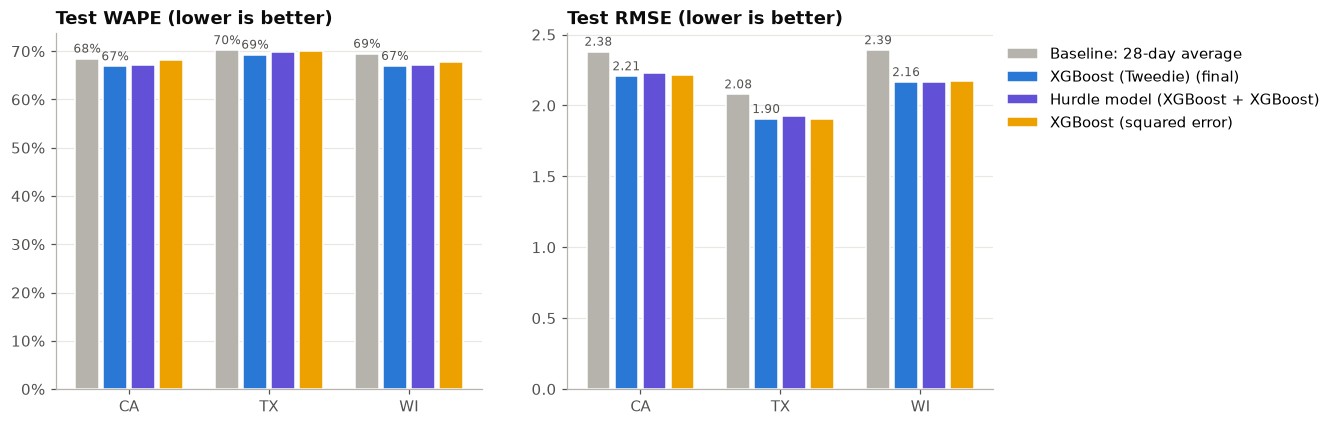

In [10]:
# One fixed color per model in this chart: gray baseline, then categorical slots 1, 7 and 4
MODEL_COLORS = dict(zip(test_models, [MUTED, "#2a78d6", "#6250d6", "#eda100"]))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, metric, fmt in [(axes[0], "WAPE", "{:.0%}"), (axes[1], "RMSE", "{:.2f}")]:
    width = 0.8 / len(test_models)
    for j, model in enumerate(test_models):
        values = test_results[test_results["model"] == model].set_index("state").loc[STATES, metric]
        label = f"{model} (final)" if model == final_model else model
        bars = ax.bar(np.arange(len(STATES)) + (j - (len(test_models) - 1) / 2) * width, values,
                      width=width - 0.03, color=MODEL_COLORS[model], label=label, edgecolor="white", linewidth=1)
        if model in (BASELINE, final_model):
            ax.bar_label(bars, [fmt.format(v) for v in values], fontsize=8, color=INK_2, padding=2)
    ax.set_xticks(np.arange(len(STATES)), STATES)
    if metric == "WAPE":
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title(f"Test {metric} (lower is better)", loc="left")
    ax.grid(axis="x", visible=False)
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))
save(fig, "02_test_shortlist")

## 5. The final model on the test set

Everything below uses the final model's test forecasts.

### 5.1 Where does it miss?

WAPE by product category, and by demand type. A product is **intermittent**
if it sold nothing on at least half of the 91 days before order day
(`zero_share_91 ≥ 0.5`), and **regular** otherwise.

In [11]:
segment_rows = []
for state, out in test_store.items():
    clean = out[out["is_suspected_stockout"] == 0].copy()
    clean["demand type"] = np.where(clean["zero_share_91"] >= 0.5, "intermittent", "regular")
    for column in ["cat_id", "demand type"]:
        for value, part in clean.groupby(column, observed=True):
            for model in [BASELINE, final_model]:
                r = regression_report(part["target_sales"], part[model])
                segment_rows.append({"state": state, "segment": column.replace("cat_id", "category"), "value": value,
                                     "model": model, "share of units": part["target_sales"].sum() / clean["target_sales"].sum(),
                                     "WAPE": r["WAPE"], "Bias": r["Bias"]})

segments = pd.DataFrame(segment_rows)
segments.to_csv(OUT_DIR / "test_segments.csv", index=False)
(segments[segments["model"] == final_model]
 .pivot_table(index=["segment", "value"], columns="state", values=["WAPE", "Bias", "share of units"])
 .style.format("{:.1%}"))

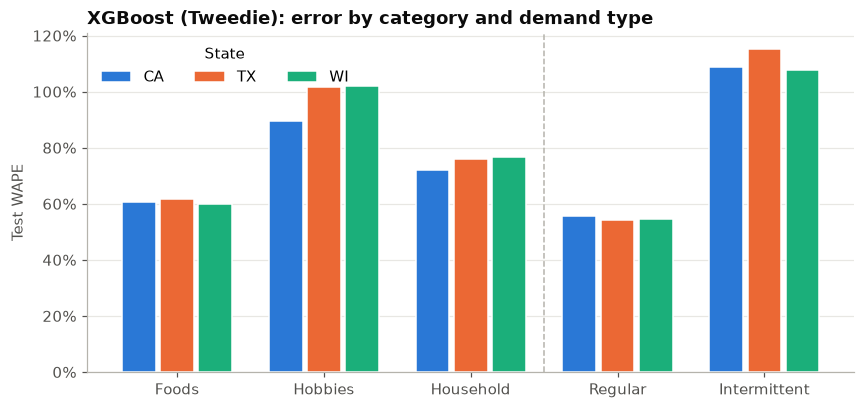

In [12]:
seg = segments[segments["model"] == final_model]
groups = [("category", v) for v in sorted(seg.loc[seg["segment"] == "category", "value"].unique())] + \
         [("demand type", "regular"), ("demand type", "intermittent")]
fig, ax = plt.subplots(figsize=(9, 4))
width = 0.26
for i, state in enumerate(STATES):
    values = [seg[(seg["state"] == state) & (seg["segment"] == g) & (seg["value"] == v)]["WAPE"].iloc[0] for g, v in groups]
    ax.bar(np.arange(len(groups)) + (i - 1) * width, values, width=width - 0.03,
           color=STATE_COLORS[state], label=state, edgecolor="white", linewidth=1)
ax.axvline(len(groups) - 2.5, color=MUTED, linewidth=1, linestyle="--")
ax.set_xticks(np.arange(len(groups)), [v.title() for _, v in groups])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Test WAPE")
ax.set_title(f"{final_model}: error by category and demand type", loc="left")
ax.legend(title="State", ncols=3, loc="upper left")
ax.grid(axis="x", visible=False)
save(fig, "03_segments")

### 5.2 Total weekly sales: forecast vs. actual

The sum of daily forecasts over every product and store in a state, week by
week, compared with actual units sold (non-stockout rows only). This checks
whether the model follows seasonal swings and holidays, not just individual
days.

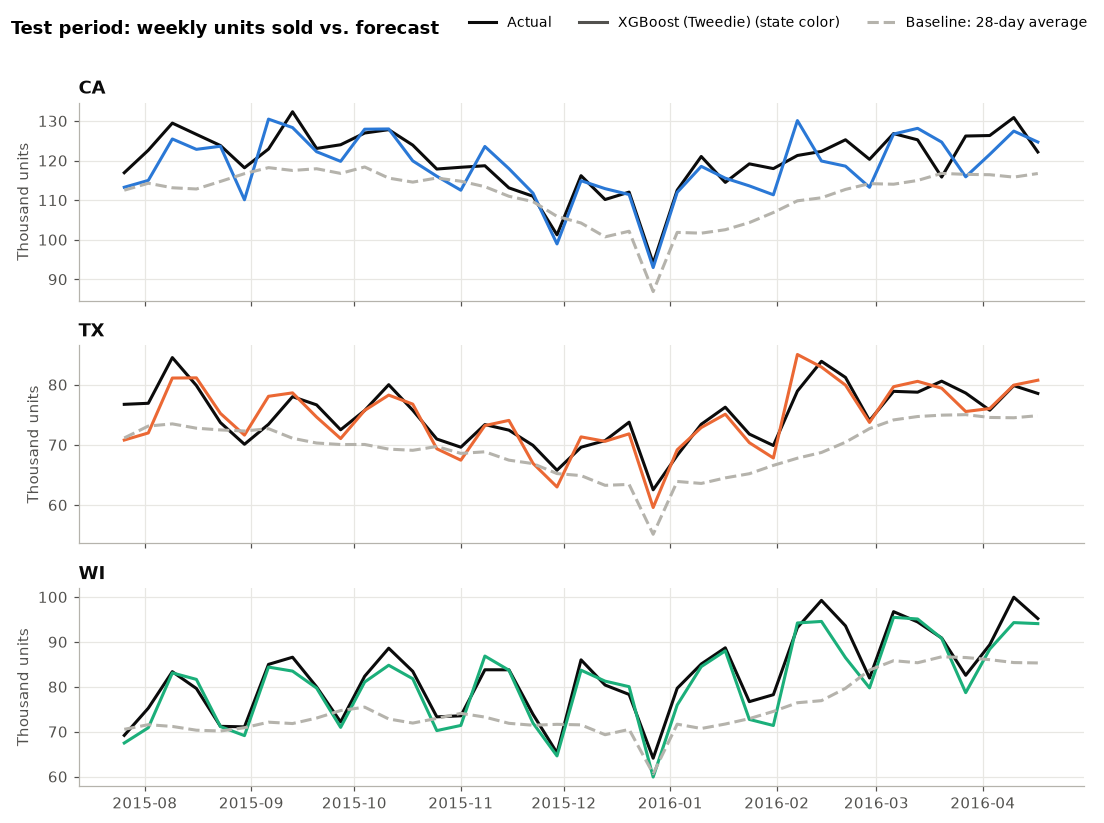

In [13]:
fig, axes = plt.subplots(len(STATES), 1, figsize=(10, 7.5), sharex=True)
for ax, state in zip(axes, STATES):
    clean = test_store[state][test_store[state]["is_suspected_stockout"] == 0]
    weekly = clean.groupby(pd.Grouper(key="date", freq="W-SUN"))[["target_sales", final_model, BASELINE]].sum()
    weekly = weekly.iloc[1:-1]                     # drop partial first and last weeks
    ax.plot(weekly.index, weekly["target_sales"] / 1e3, color=INK, linewidth=2, label="Actual")
    ax.plot(weekly.index, weekly[final_model] / 1e3, color=STATE_COLORS[state], linewidth=2, label=final_model)
    ax.plot(weekly.index, weekly[BASELINE] / 1e3, color=MUTED, linewidth=2, linestyle="--", label=BASELINE)
    ax.set_ylabel("Thousand units")
    ax.set_title(state, loc="left")
fig.suptitle("Test period: weekly units sold vs. forecast", x=0.01, ha="left", fontweight="bold")
fig.legend(handles=[plt.Line2D([], [], color=INK, linewidth=2),
                    plt.Line2D([], [], color=INK_2, linewidth=2),
                    plt.Line2D([], [], color=MUTED, linewidth=2, linestyle="--")],
           labels=["Actual", f"{final_model} (state color)", BASELINE],
           loc="upper right", ncols=3, fontsize=9, bbox_to_anchor=(1, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.97))
save(fig, "04_weekly_totals")

### 5.3 Business impact

Forecast errors converted to dollars at shelf price, per store per week:

- **Over-forecast:** units the forecast expected that did not sell (excess
  stock, tying up cash and shelf space).
- **Under-forecast:** units that sold beyond the forecast (sales an order
  based on the forecast would not have covered).

These are values at selling price, not profit. A real cost model would
weigh the two kinds of error differently.

**Lost sales on suspected stockouts:** on a suspected stockout, recorded
sales are 0, but the model still forecasts demand. Summing those forecasts
gives a rough estimate of the sales lost to empty shelves.

In [14]:
impact_rows = []
for state, out in test_store.items():
    clean = out[out["is_suspected_stockout"] == 0]
    stockout = out[out["is_suspected_stockout"] == 1]
    store_weeks = out["store_id"].nunique() * out["date"].nunique() / 7
    for model in [BASELINE, final_model]:
        value = forecast_value(clean["target_sales"], clean[model], clean["sell_price"])
        impact_rows.append({
            "state": state, "model": model,
            "over-forecast $ / store-week": value["over ($)"] / store_weeks,
            "under-forecast $ / store-week": value["under ($)"] / store_weeks,
            "total error $ / store-week": (value["over ($)"] + value["under ($)"]) / store_weeks,
            "sales $ / store-week": (clean["target_sales"] * clean["sell_price"]).sum() / store_weeks,
            "est. lost sales on stockouts $ / store-week": (stockout[model] * stockout["sell_price"]).sum() / store_weeks,
        })

impact = pd.DataFrame(impact_rows)
impact.to_csv(OUT_DIR / "business_impact.csv", index=False)
change = pd.DataFrame({
    kind: impact.pivot(index="state", columns="model", values=f"{kind} $ / store-week")
          .pipe(lambda t: t[final_model] / t[BASELINE] - 1)
    for kind in ["under-forecast", "over-forecast", "total error"]
})
print(f"Change in mis-forecast value, {final_model} vs. the baseline:")
print(change.map("{:+.1%}".format).to_string())
impact.set_index(["state", "model"]).style.format("${:,.0f}")

Change in mis-forecast value, XGBoost (Tweedie) vs. the baseline:
      under-forecast over-forecast total error
state                                         
CA             -8.2%         +5.6%       -1.9%
TX             -7.3%         +6.7%       -0.9%
WI             -9.5%         +5.8%       -2.6%


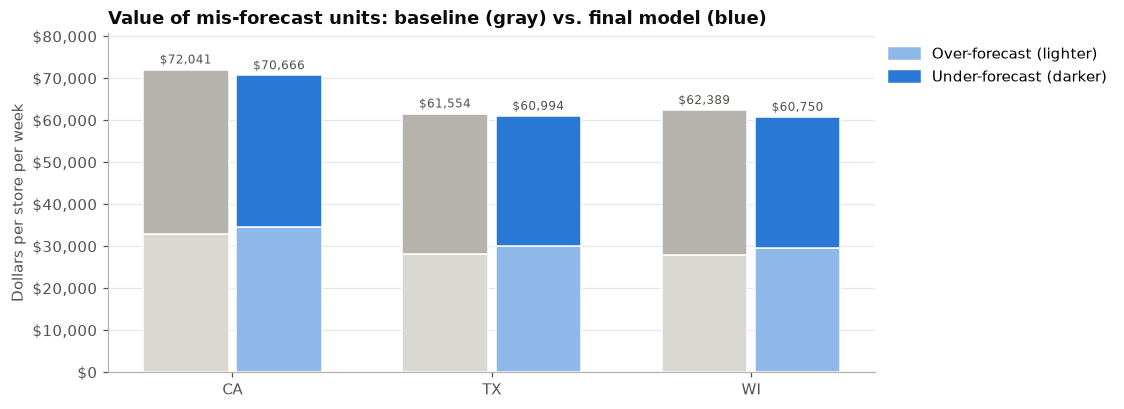

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
width = 0.36
for j, model in enumerate([BASELINE, final_model]):
    rows = impact[impact["model"] == model].set_index("state").loc[STATES]
    x = np.arange(len(STATES)) + (j - 0.5) * width
    light, dark = ("#d9d8d3", MUTED) if model == BASELINE else ("#8fb8ea", "#2a78d6")
    ax.bar(x, rows["over-forecast $ / store-week"], width=width - 0.03, color=light, edgecolor="white", linewidth=1)
    bars = ax.bar(x, rows["under-forecast $ / store-week"], bottom=rows["over-forecast $ / store-week"],
                  width=width - 0.03, color=dark, edgecolor="white", linewidth=1)
    ax.bar_label(bars, [f"${v:,.0f}" for v in rows["total error $ / store-week"]], fontsize=8, color=INK_2, padding=2)
ax.set_xticks(np.arange(len(STATES)), STATES)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_ylabel("Dollars per store per week")
ax.set_title("Value of mis-forecast units: baseline (gray) vs. final model (blue)", loc="left")
ax.set_ylim(0, impact["total error $ / store-week"].max() * 1.12)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#8fb8ea", "#2a78d6"]],
          labels=["Over-forecast (lighter)", "Under-forecast (darker)"],
          loc="upper left", bbox_to_anchor=(1, 1))
ax.grid(axis="x", visible=False)
save(fig, "05_business_impact")

## 6. Summary

The table below has the final model's test scores in every state. These are
the numbers for the Results slide. All figures are saved in
`results/evaluation/figures/`.

In [16]:
final = test_results[test_results["model"] == final_model].set_index("state")[METRICS]
base = test_results[test_results["model"] == BASELINE].set_index("state")
final["RMSE gain vs baseline"] = 1 - final["RMSE"] / base["RMSE"]
final["WAPE gain vs baseline (points)"] = (base["WAPE"] - final["WAPE"]) * 100
final.to_csv(OUT_DIR / "final_model_test.csv")
print("Final model:", final_model)
final.style.format({**FMT, "RMSE gain vs baseline": "{:.1%}", "WAPE gain vs baseline (points)": "{:.1f}"})

Final model: XGBoost (Tweedie)


,MAE,RMSE,WAPE,Bias,Poisson deviance,RMSSE,R2,RMSE gain vs baseline,WAPE gain vs baseline (points)
state,,,,,,,,,
CA,1.098,2.206,66.9%,-1.2%,1.465,0.879,0.692,7.3%,1.6
TX,0.950,1.904,69.3%,-0.7%,1.329,0.828,0.740,8.4%,0.9
WI,1.007,2.164,66.9%,-2.2%,1.355,0.862,0.680,9.4%,2.5
